# AI Layoffs Register: Exploratory Insights

This notebook explores `ai-layoffs-register.csv`, a source-cited register of layoff and workforce-reduction
events that companies, filings or credible reporting have linked to AI (2023 → 2026).

**Key concepts from the README, which you need to read the numbers correctly:**

| Column | Meaning |
|---|---|
| `Roles counted` | Headcount that meets the register's bar for an AI-attributed cut (employer named AI *and* stated the number). |
| `Roles reported (not counted)` | Headcount reported for the event but deliberately **set aside** (e.g. employer never named AI, press/union figure, "up to" limits, attrition). |
| `Attribution` | `explicit` = employer names AI as *the* cause · `mixed` = AI is one factor among others · `blamed` = others link it to AI, the employer does not. |
| `Evidence tier` | Tier 1 = filing/company statement · Tier 2 = credible named reporting · Tier 3 = weaker signal. |
| `Kind` | `cut` vs `workforce statement` (a statement about AI and headcount, **not** a layoff, so it's excluded from cut counts). |

Sections:
1. Setup & cleaning
2. Overview
3. How fast is it growing? (timeline)
4. Counted vs. reported: how much of the headline is "really" AI?
5. How strong is the AI link? (attribution × evidence)
6. Who is cutting? (sectors, countries, repeat companies)
7. What kind of work is being cut? (job families)
8. How big are the cuts? (size and % of workforce)
9. Did the cuts actually happen? (execution status)
10. Key takeaways

## 1. Setup & cleaning

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option("display.max_colwidth", 80)

# Reference palette: categorical slots are used in this fixed order, never cycled.
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
GRAY = "#b8b6ae"          # neutral "other / not counted" marks
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]  # one-hue blue ramp

plt.rcParams.update({
    "figure.figsize": (11, 4.8), "figure.dpi": 110,
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.titlepad": 12,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.7, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "legend.labelcolor": INK2,
    "font.family": ["Segoe UI", "DejaVu Sans", "sans-serif"],
})
thousands = mticker.FuncFormatter(lambda x, _: f"{x:,.0f}")

df = pd.read_csv("ai-layoffs-register.csv", encoding="utf-8-sig")
print(df.shape)
df.head(3)

(382, 20)


,Company,Date,Sector,Country,Functions,Roles counted,Roles reported (not counted),Why not counted,% of workforce,Evidence tier,Attribution,Execution,Counts in US index,Claim,Source,Source URL,Event ID,Kind,What the employer said,Job families
0,Umicore,2026-11-12,Chemicals / Materials (advanced materials and metals recycling),Belgium (headquarters; the job losses fall mostly in enterprise functions ac...,Enterprise (corporate support) functions across several regions (Umicore's r...,NaN,350.0,"The company gave only an upper limit (""up to""), not a number.","up to about 3% (our arithmetic: up to about 350 of the more than 11,000 empl...",Tier 1,mixed,announced,no,"Umicore, press release ""Umicore to invest €450 million for growth; intends t...",Umicore: Umicore to invest €450 million for growth; intends to strengthen op...,https://www.umicore.com/en/media/newsroom/umicore-to-invest-450-million-euro...,umicore-2026-11,cut,Cited AI among other reasons,Corporate functions
1,San Benedetto,2026-11-10,Beverages (mineral water and soft drinks),Italy,Not specified,NaN,120.0,The company has not named AI as the cause; the employer says the reduction w...,"about 12% (120 of 1,001 employees, both in the company's note)",Tier 2,blamed,announced,no,"Il Post (November 10, 2026), after ""Secondo quanto detto dai sindacati"" (acc...",Il Post: San Benedetto ha annunciato 120 licenziamenti e una riorganizzazion...,https://www.ilpost.it/2026/11/10/san-benedetto-licenziamenti-aumento-costi-a...,san-benedetto-2026-11,cut,Named no AI reason; others linked it to AI,Not specified
2,Paramount Skydance,2026-11-09,Media and entertainment,United States (company-wide programme; no country split given),No roles cut yet (a programme: consolidating redundant back-office and corpo...,NaN,NaN,NaN,NaN,Tier 1,mixed,announced,no,"Skydance Corp's Q3 2026 letter to shareholders (SEC Form 8-K, Exhibit 99, No...","Skydance Corp: Q3 2026 letter to shareholders (SEC Form 8-K, Exhibit 99)",https://www.sec.gov/Archives/edgar/data/2041610/000204161026000062/ex99_q326...,paramount-skydance-2026-11,workforce statement,Spoke about AI and headcount; no cut announced,Not specified


In [2]:
# --- Dates -------------------------------------------------------------------------------
df["Date"] = pd.to_datetime(df["Date"])
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.to_period("M")
df["Quarter"] = df["Date"].dt.to_period("Q")

# --- Headline headcount: the counted figure if there is one, else the reported one ---------
df["Roles any"] = df["Roles counted"].fillna(df["Roles reported (not counted)"])
df["Figure status"] = np.select(
    [df["Roles counted"].notna(), df["Roles reported (not counted)"].notna()],
    ["Counted", "Reported, set aside"], default="No figure")

# --- % of workforce: free text -> first percentage mentioned ------------------------------
df["Pct workforce"] = pd.to_numeric(
    df["% of workforce"].str.extract(r"(\d+(?:\.\d+)?)\s*%")[0], errors="coerce")

# --- Country: free text -> the first named country ---------------------------------------
df["Country main"] = df["Country"].str.split(r" \(|,|;").str[0].str.strip()

# --- Sector: ~250 free-text labels -> 10 groups (rules checked in order) -----------------
SECTOR_RULES = [
    ("Crypto",                       ["crypto", "bitcoin", "blockchain", "digital asset"]),
    ("Banking, finance & insurance", ["bank", "fintech", "payment", "insurance", "mortgage", "financial",
                                      "asset management", "wealth", "credit"]),
    ("Telecom",                      ["telecom"]),
    ("Big Tech",                     ["big tech"]),
    ("IT services, BPO & consulting",["it services", "bpo", "call center", "consulting", "professional services",
                                      "it solutions", "contact centres and business", "data analytics and digital"]),
    ("Education",                    ["education", "course", "training", "upskilling", "test preparation"]),
    ("Software & internet",          ["software", "saas", "cyber", "cloud", "social", "dev", "internet", "artificial",
                                      "ai ", "tech", "app", "games", "gaming", "data", "geospatial", "semiconductor",
                                      "hardware"]),
    ("Media, publishing & ads",      ["media", "news", "broadcast", "publish", "radio", "entertainment", "advertis",
                                      "audience", "journalism"]),
    ("Retail, e-commerce & travel",  ["e-commerce", "retail", "grocery", "marketplace", "fashion", "delivery",
                                      "travel", "airline", "ticketing", "home", "styling", "logistics", "freight"]),
    ("Government & public sector",   ["government", "public"]),
]
def sector_group(s: str) -> str:
    s = str(s).lower()
    for group, keys in SECTOR_RULES:
        if any(k in s for k in keys):
            return group
    return "Other industries"
df["Sector group"] = df["Sector"].map(sector_group)

# --- Job families: "; "-separated list -> one row per family ------------------------------
jobs = (df.assign(Family=df["Job families"].str.split("; "))
          .explode("Family"))

# Most analyses are about layoffs, so keep workforce statements out of them.
cuts = df[df["Kind"] == "cut"].copy()
print(f"{len(df)} events  |  {len(cuts)} cuts  |  {(df['Kind'] != 'cut').sum()} workforce statements")
df["Sector group"].value_counts()

382 events  |  353 cuts  |  29 workforce statements


Sector group
Software & internet              152
Banking, finance & insurance      72
Retail, e-commerce & travel       31
Media, publishing & ads           29
Telecom                           24
Other industries                  22
Big Tech                          14
Education                         13
IT services, BPO & consulting     13
Crypto                             9
Government & public sector         3
Name: count, dtype: int64

## 2. Overview

In [3]:
overview = pd.Series({
    "Events": len(df),
    "Distinct companies": df["Company"].nunique(),
    "Date range": f"{df['Date'].min():%Y-%m-%d} → {df['Date'].max():%Y-%m-%d}",
    "Countries (first named)": df["Country main"].nunique(),
    "Cuts / workforce statements": f"{len(cuts)} / {len(df) - len(cuts)}",
    "Roles counted (AI-attributed, stated)": f"{df['Roles counted'].sum():,.0f}  ({df['Roles counted'].notna().sum()} events)",
    "Roles reported but set aside": f"{df['Roles reported (not counted)'].sum():,.0f}  ({df['Roles reported (not counted)'].notna().sum()} events)",
    "Events with no headcount at all": int((df["Figure status"] == "No figure").sum()),
    "Sourced to SEC filings": int(df["Source URL"].str.contains("sec.gov", na=False).sum()),
}, name="Value")
overview.to_frame()

,Value
Events,382
Distinct companies,309
Date range,2023-02-22 → 2026-11-12
Countries (first named),36
Cuts / workforce statements,353 / 29
"Roles counted (AI-attributed, stated)","103,766 (108 events)"
Roles reported but set aside,"346,696 (194 events)"
Events with no headcount at all,80
Sourced to SEC filings,78


## 3. How fast is it growing?

Monthly event counts, split by how strongly the AI link is stated.

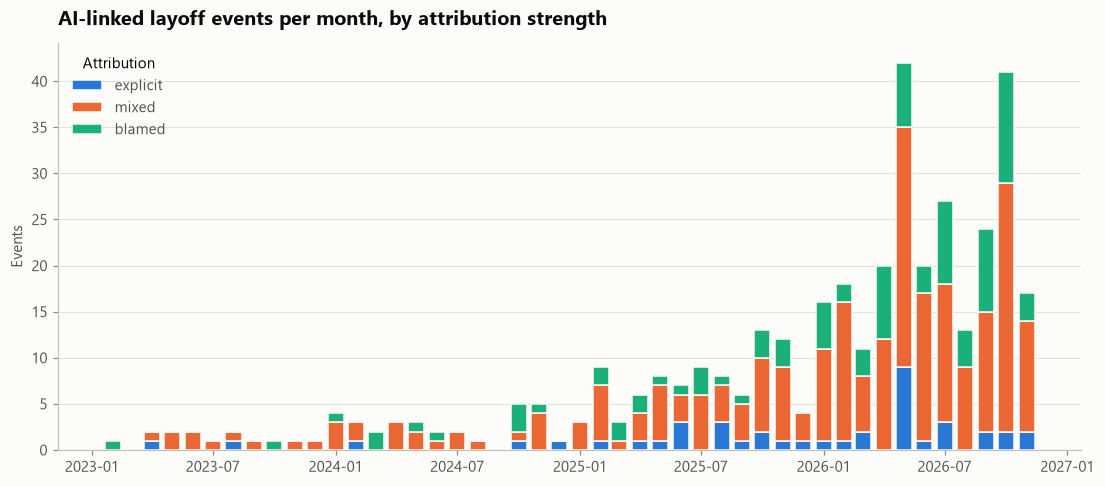

,events,companies,events (annualised)
Year,,,
2023,14,14,14.0
2024,31,28,31.0
2025,88,82,88.0
2026,249,233,288.0


In [4]:
ATTR = ["explicit", "mixed", "blamed"]
ATTR_COLOR = dict(zip(ATTR, C[:3]))

monthly = (df.groupby(["Month", "Attribution"]).size().unstack(fill_value=0)
             .reindex(columns=ATTR, fill_value=0))
monthly = monthly.reindex(pd.period_range(monthly.index.min(), monthly.index.max(), freq="M"), fill_value=0)

fig, ax = plt.subplots(figsize=(12, 4.8))
x = monthly.index.to_timestamp()
bottom = np.zeros(len(monthly))
for a in ATTR:
    ax.bar(x, monthly[a], bottom=bottom, width=24, color=ATTR_COLOR[a], label=a,
           edgecolor="#fcfcfb", linewidth=1)
    bottom += monthly[a].values
ax.set_title("AI-linked layoff events per month, by attribution strength")
ax.set_ylabel("Events")
ax.legend(title="Attribution", loc="upper left")
ax.grid(axis="x", visible=False)
plt.show()

yearly = df.groupby("Year").agg(events=("Company", "size"), companies=("Company", "nunique"))
# Annualise the current (partial) year so it's comparable.
last = df["Date"].max()
yearly["events (annualised)"] = yearly["events"].astype(float)
yearly.loc[last.year, "events (annualised)"] = round(yearly.loc[last.year, "events"] * 365 / last.dayofyear, 0)
yearly

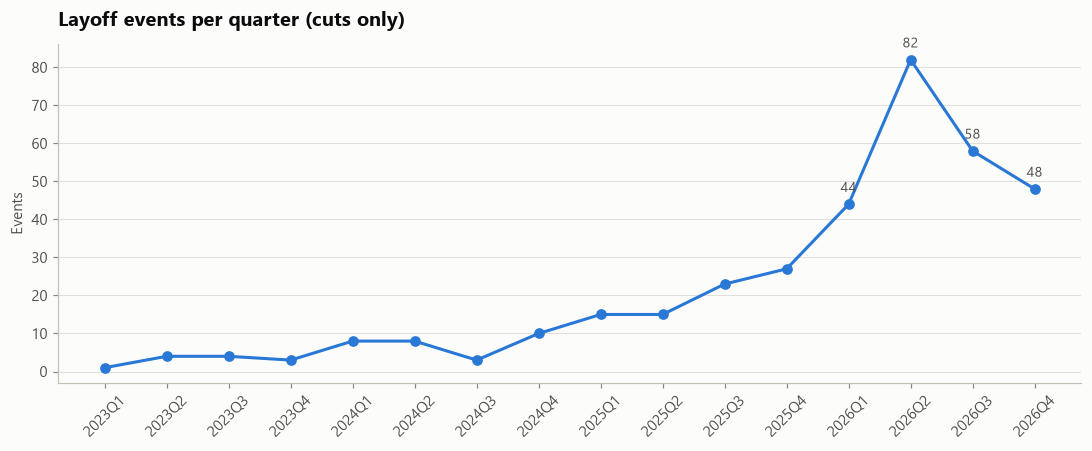

Note: 2026Q4 is partial (data ends 2026-11-12).


In [5]:
# Quarter-over-quarter momentum, cuts only.
q = cuts.groupby("Quarter").size()
q = q.reindex(pd.period_range(q.index.min(), q.index.max(), freq="Q"), fill_value=0)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(q.index.astype(str), q.values, color=C[0], linewidth=2, marker="o", markersize=6)
for i, v in enumerate(q.values):
    if i >= len(q) - 4:                              # label only the most recent quarters
        ax.annotate(f"{v}", (i, v), textcoords="offset points", xytext=(0, 8),
                    ha="center", color=INK2, fontsize=9)
ax.set_title("Layoff events per quarter (cuts only)")
ax.set_ylabel("Events")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="x", visible=False)
plt.show()
print(f"Note: {last.to_period('Q')} is partial (data ends {last:%Y-%m-%d}).")

## 4. Counted vs. reported: how much of the headline is "really" AI?

Press headlines usually add up every reported number. The register only *counts* a figure when the employer
itself named AI and stated the number. The gap between the two is one of the most useful findings here.

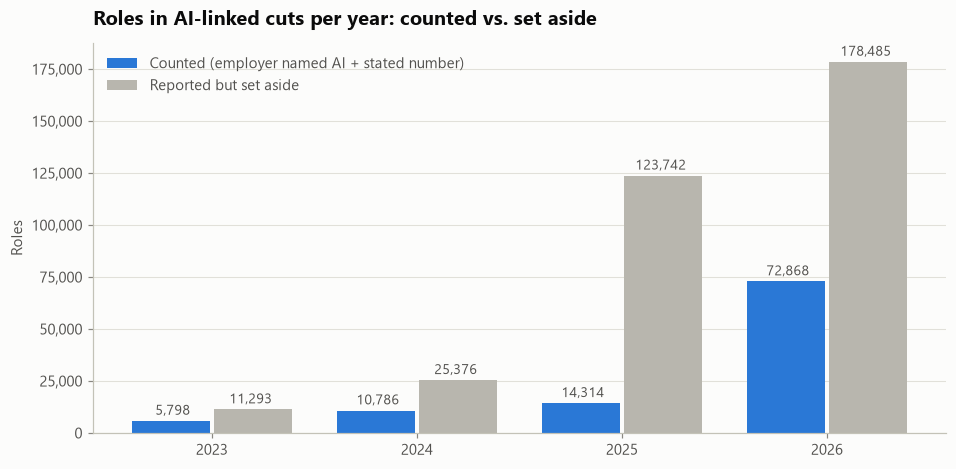

,Roles counted,Roles reported (not counted),Counted share %
Year,,,
2023,"5,798","11,293",33.9
2024,"10,786","25,376",29.8
2025,"14,314","123,742",10.4
2026,"72,868","178,485",29.0


In [6]:
roles_year = cuts.groupby("Year")[["Roles counted", "Roles reported (not counted)"]].sum()
roles_year["Counted share %"] = (100 * roles_year["Roles counted"]
                                 / roles_year[["Roles counted", "Roles reported (not counted)"]].sum(axis=1)).round(1)

fig, ax = plt.subplots(figsize=(10, 4.6))
w = 0.38
xs = np.arange(len(roles_year))
ax.bar(xs - w/2 - 0.01, roles_year["Roles counted"], w, color=C[0], label="Counted (employer named AI + stated number)")
ax.bar(xs + w/2 + 0.01, roles_year["Roles reported (not counted)"], w, color=GRAY, label="Reported but set aside")
for i, (c, r) in enumerate(zip(roles_year["Roles counted"], roles_year["Roles reported (not counted)"])):
    ax.annotate(f"{c:,.0f}", (i - w/2, c), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9, color=INK2)
    ax.annotate(f"{r:,.0f}", (i + w/2, r), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=9, color=INK2)
ax.set_xticks(xs, roles_year.index)
ax.yaxis.set_major_formatter(thousands)
ax.set_title("Roles in AI-linked cuts per year: counted vs. set aside")
ax.set_ylabel("Roles")
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
plt.show()
roles_year.style.format({"Roles counted": "{:,.0f}", "Roles reported (not counted)": "{:,.0f}", "Counted share %": "{:.1f}"})

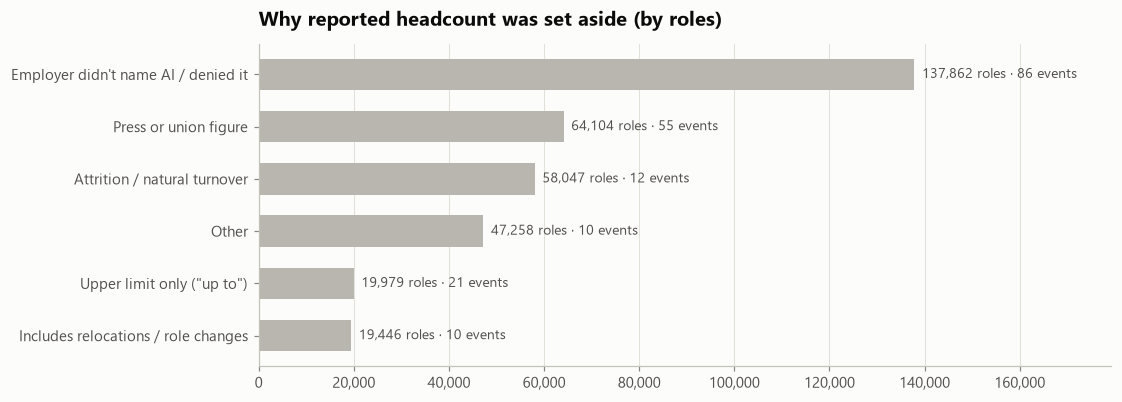

In [7]:
# Why do reported figures get set aside? Group the free-text reasons into themes.
REASONS = [
    ("Employer didn't name AI / denied it", r"has not named AI|did not name|not caused by AI|names no AI|denied|not a reason|no AI"),
    ("Upper limit only (\"up to\")",         r"upper limit|up to"),
    ("Press or union figure",               r"press|union|reported by|source"),
    ("Attrition / natural turnover",        r"attrition|turnover|voluntary"),
    ("Includes relocations / role changes", r"relocat|moved|transfer|redeploy"),
]
why = df.loc[df["Why not counted"].notna(), "Why not counted"]
reason = pd.Series("Other", index=why.index)
for label, pat in reversed(REASONS):                 # first matching rule wins
    reason[why.str.contains(pat, case=False, regex=True)] = label
reason_tbl = (pd.DataFrame({"reason": reason, "roles": df.loc[why.index, "Roles reported (not counted)"]})
                .groupby("reason").agg(events=("roles", "size"), roles=("roles", "sum"))
                .sort_values("roles"))

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(reason_tbl.index, reason_tbl["roles"], color=GRAY, height=0.6)
for i, (r, e) in enumerate(zip(reason_tbl["roles"], reason_tbl["events"])):
    ax.annotate(f"{r:,.0f} roles · {e} events", (r, i), xytext=(5, 0), textcoords="offset points",
                va="center", fontsize=9, color=INK2)
ax.xaxis.set_major_formatter(thousands)
ax.set_xlim(0, reason_tbl["roles"].max() * 1.3)
ax.set_title("Why reported headcount was set aside (by roles)")
ax.grid(axis="y", visible=False)
plt.show()

## 5. How strong is the AI link?

Attribution strength vs. evidence quality, and how employers themselves frame the cuts.

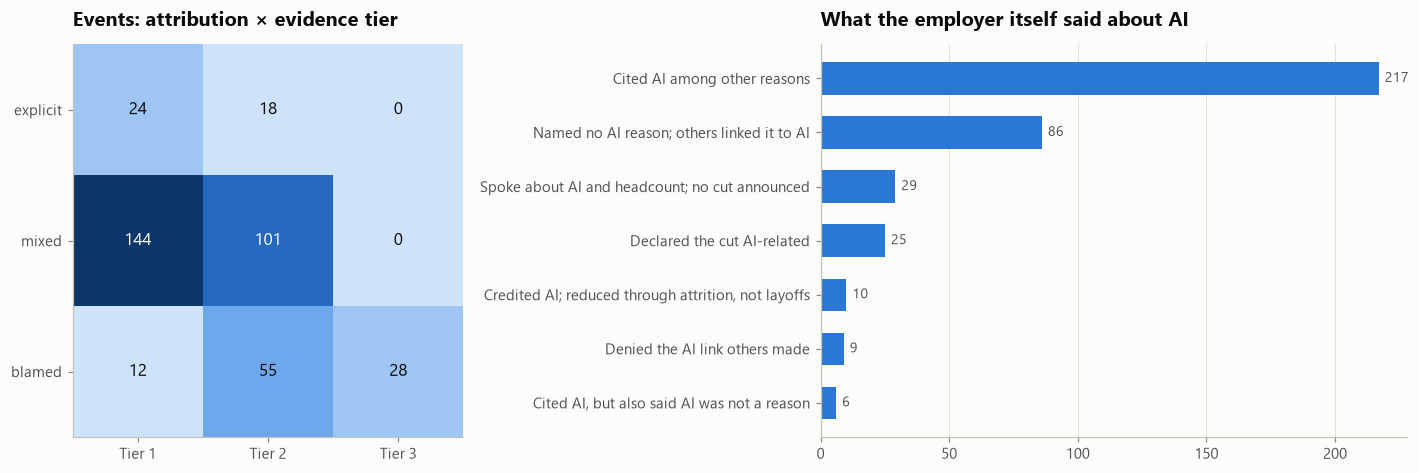

Only 11% of events have an employer explicitly naming AI as the cause.


In [8]:
ct = pd.crosstab(df["Attribution"], df["Evidence tier"]).reindex(ATTR)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1.5]})
ax = axes[0]
im = ax.imshow(ct.values, cmap=plt.matplotlib.colors.ListedColormap(SEQ), aspect="auto")
for (i, j), v in np.ndenumerate(ct.values):
    ax.text(j, i, v, ha="center", va="center", fontsize=11,
            color="#ffffff" if v > ct.values.max() * 0.5 else INK)
ax.set_xticks(range(ct.shape[1]), ct.columns)
ax.set_yticks(range(ct.shape[0]), ct.index)
ax.grid(False)
ax.set_title("Events: attribution × evidence tier")

said = df["What the employer said"].value_counts().sort_values()
ax = axes[1]
ax.barh(said.index, said.values, color=C[0], height=0.6)
for i, v in enumerate(said.values):
    ax.annotate(str(v), (v, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=INK2)
ax.set_title("What the employer itself said about AI")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

explicit_share = (df["Attribution"] == "explicit").mean() * 100
print(f"Only {explicit_share:.0f}% of events have an employer explicitly naming AI as the cause.")

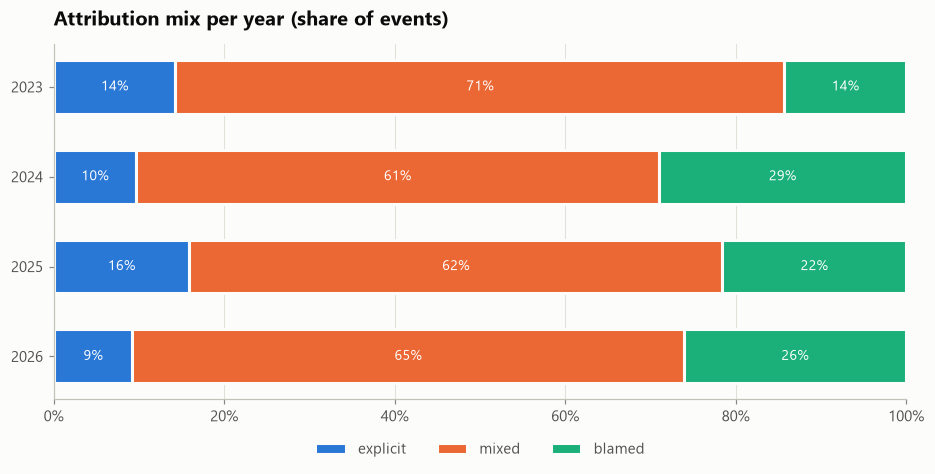

In [9]:
# Is attribution getting stronger or weaker over time? Share of events per year.
attr_year = pd.crosstab(df["Year"], df["Attribution"], normalize="index").reindex(columns=ATTR) * 100

fig, ax = plt.subplots(figsize=(10, 4.2))
left = np.zeros(len(attr_year))
for a in ATTR:
    ax.barh(attr_year.index.astype(str), attr_year[a], left=left, color=ATTR_COLOR[a], label=a,
            edgecolor="#fcfcfb", linewidth=2, height=0.6)
    for i, (l, v) in enumerate(zip(left, attr_year[a])):
        if v >= 8:
            ax.text(l + v/2, i, f"{v:.0f}%", ha="center", va="center", color="#ffffff", fontsize=9)
    left += attr_year[a].values
ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(mticker.PercentFormatter())
ax.set_title("Attribution mix per year (share of events)")
ax.legend(ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.2))
ax.grid(axis="y", visible=False)
plt.show()

## 6. Who is cutting?

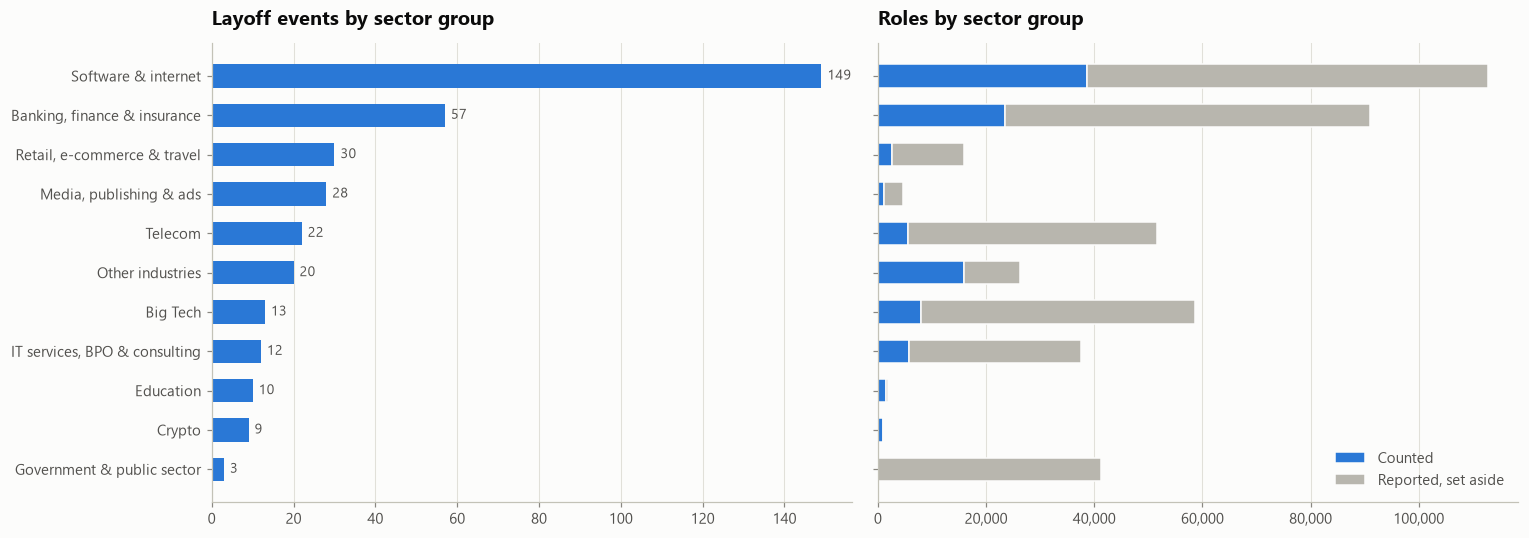

,events,roles_counted,roles_reported
Sector group,,,
Software & internet,149,"38,647","74,067"
"Banking, finance & insurance",57,"23,560","67,497"
"Retail, e-commerce & travel",30,"2,697","13,200"
"Media, publishing & ads",28,"1,137","3,463"
Telecom,22,"5,617","45,904"
Other industries,20,"15,932","10,284"
Big Tech,13,"8,000","50,600"
"IT services, BPO & consulting",12,"5,760","31,818"
Education,10,"1,476",466


In [10]:
sec = (cuts.groupby("Sector group")
           .agg(events=("Company", "size"), roles_counted=("Roles counted", "sum"),
                roles_reported=("Roles reported (not counted)", "sum"))
           .sort_values("events"))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
axes[0].barh(sec.index, sec["events"], color=C[0], height=0.6)
for i, v in enumerate(sec["events"]):
    axes[0].annotate(str(v), (v, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=INK2)
axes[0].set_title("Layoff events by sector group")
axes[0].grid(axis="y", visible=False)

axes[1].barh(sec.index, sec["roles_counted"], color=C[0], height=0.6, label="Counted",
             edgecolor="#fcfcfb", linewidth=1)
axes[1].barh(sec.index, sec["roles_reported"], left=sec["roles_counted"], color=GRAY, height=0.6,
             label="Reported, set aside", edgecolor="#fcfcfb", linewidth=1)
axes[1].xaxis.set_major_formatter(thousands)
axes[1].set_title("Roles by sector group")
axes[1].legend(loc="lower right")
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
sec.sort_values("events", ascending=False).style.format("{:,.0f}")

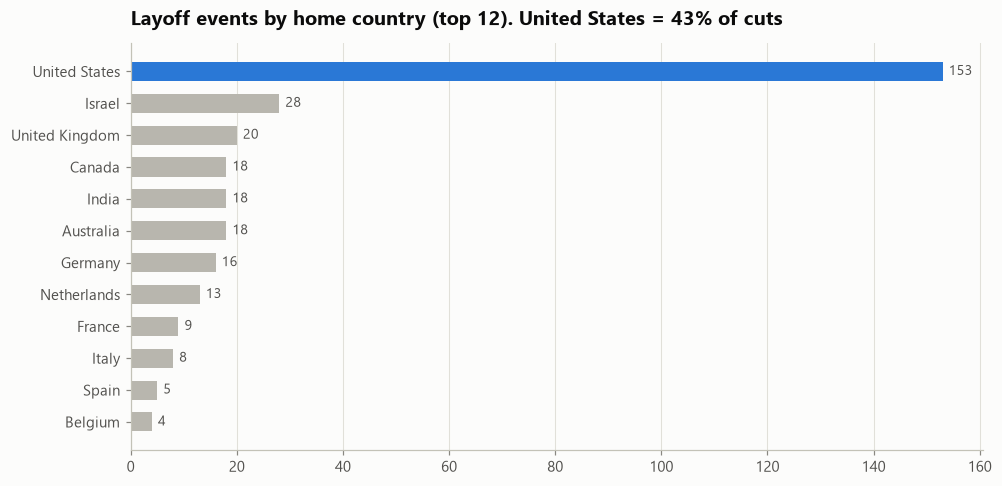

In [11]:
top_countries = cuts["Country main"].value_counts().head(12).sort_values()
us_share = (cuts["Country main"] == "United States").mean() * 100

fig, ax = plt.subplots(figsize=(10, 4.8))
colors = [C[0] if c == "United States" else GRAY for c in top_countries.index]
ax.barh(top_countries.index, top_countries.values, color=colors, height=0.6)
for i, v in enumerate(top_countries.values):
    ax.annotate(str(v), (v, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=INK2)
ax.set_title(f"Layoff events by home country (top 12). United States = {us_share:.0f}% of cuts")
ax.grid(axis="y", visible=False)
plt.show()

In [12]:
# Repeat offenders: companies with several AI-linked events.
repeat = (df.groupby("Company")
            .agg(events=("Event ID", "size"),
                 first=("Date", "min"), last=("Date", "max"),
                 roles_any=("Roles any", "sum"),
                 attribution=("Attribution", lambda s: ", ".join(sorted(s.unique()))))
            .query("events >= 3")
            .sort_values(["events", "roles_any"], ascending=False))
repeat["first"] = repeat["first"].dt.date
repeat["last"] = repeat["last"].dt.date
print(f"{(df.groupby('Company').size() > 1).sum()} companies appear more than once.")
repeat.style.format({"roles_any": "{:,.0f}"})

52 companies appear more than once.


,events,first,last,roles_any,attribution
Company,,,,,
Amazon,5,2023-11-17,2026-07-22,"30,000","blamed, explicit, mixed"
IBM,5,2023-05-01,2026-01-27,"10,763","blamed, mixed"
Chegg,5,2023-06-12,2025-10-27,"1,476",mixed
TikTok,5,2024-10-09,2026-08-05,"1,181",blamed
Google,5,2024-01-10,2026-06-04,200,"blamed, mixed"
Microsoft,3,2025-05-13,2026-07-06,"19,800",blamed
Meta,3,2025-10-22,2026-05-20,"9,600","blamed, mixed"
Telstra,3,2024-05-21,2026-02-10,"3,550","blamed, mixed"
Klarna,3,2024-02-27,2025-06-04,"1,000",explicit


## 7. What kind of work is being cut?

Using the register's own `Job families` coding (an event can touch several families).

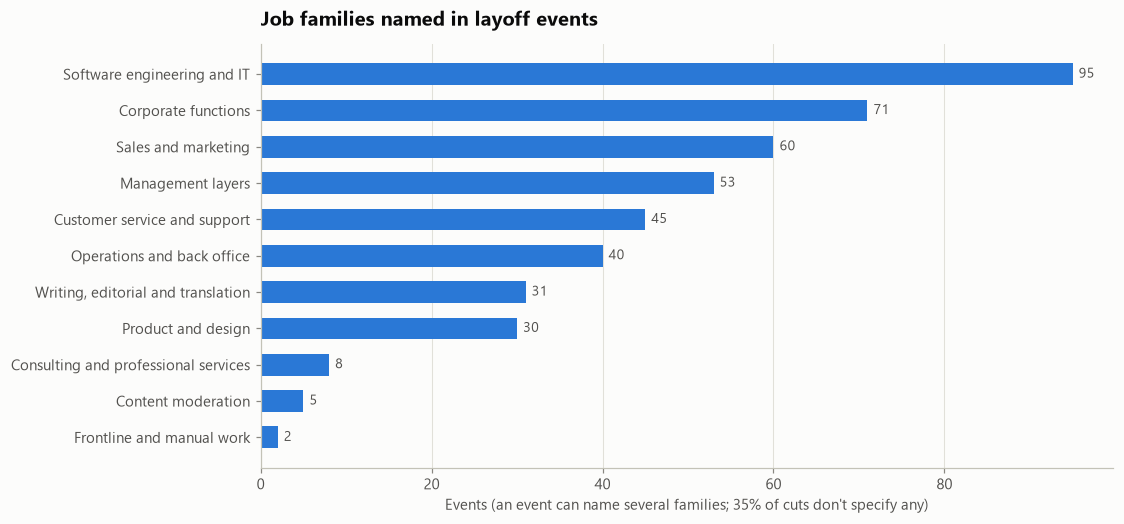

In [13]:
jf = jobs[(jobs["Kind"] == "cut") & (jobs["Family"] != "Not specified")]
fam = jf["Family"].value_counts().sort_values()
not_spec = (cuts["Job families"] == "Not specified").mean() * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(fam.index, fam.values, color=C[0], height=0.6)
for i, v in enumerate(fam.values):
    ax.annotate(str(v), (v, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=INK2)
ax.set_title("Job families named in layoff events")
ax.set_xlabel(f"Events (an event can name several families; {not_spec:.0f}% of cuts don't specify any)")
ax.grid(axis="y", visible=False)
plt.show()

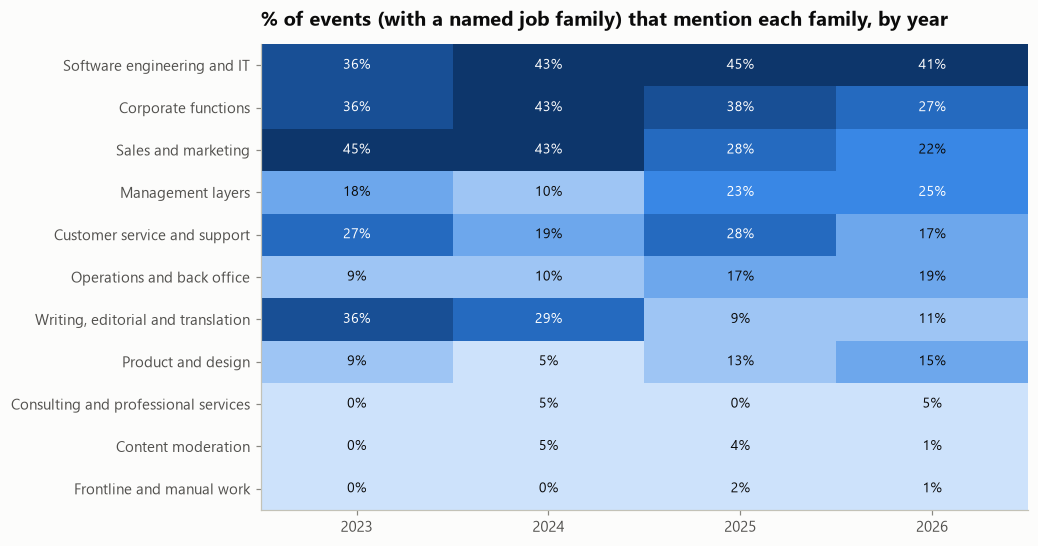

Year,2023,2024,2025,2026
events with a named family,11,21,47,150


In [14]:
# Which job families are rising? Share of events (with a named family) mentioning each, per year.
fam_year = (jf.groupby(["Family", "Year"]).size().unstack(fill_value=0)
              .div(jf.groupby("Year")["Event ID"].nunique(), axis=1) * 100)
fam_year = fam_year.loc[fam.index[::-1]]         # same order as the bar chart, biggest first

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.imshow(fam_year.values, cmap=plt.matplotlib.colors.ListedColormap(SEQ), aspect="auto")
for (i, j), v in np.ndenumerate(fam_year.values):
    ax.text(j, i, f"{v:.0f}%", ha="center", va="center", fontsize=9,
            color="#ffffff" if v > fam_year.values.max() * 0.5 else INK)
ax.set_xticks(range(fam_year.shape[1]), fam_year.columns)
ax.set_yticks(range(fam_year.shape[0]), fam_year.index)
ax.grid(False)
ax.set_title("% of events (with a named job family) that mention each family, by year")
plt.show()
jf.groupby("Year")["Event ID"].nunique().rename("events with a named family").to_frame().T

## 8. How big are the cuts?

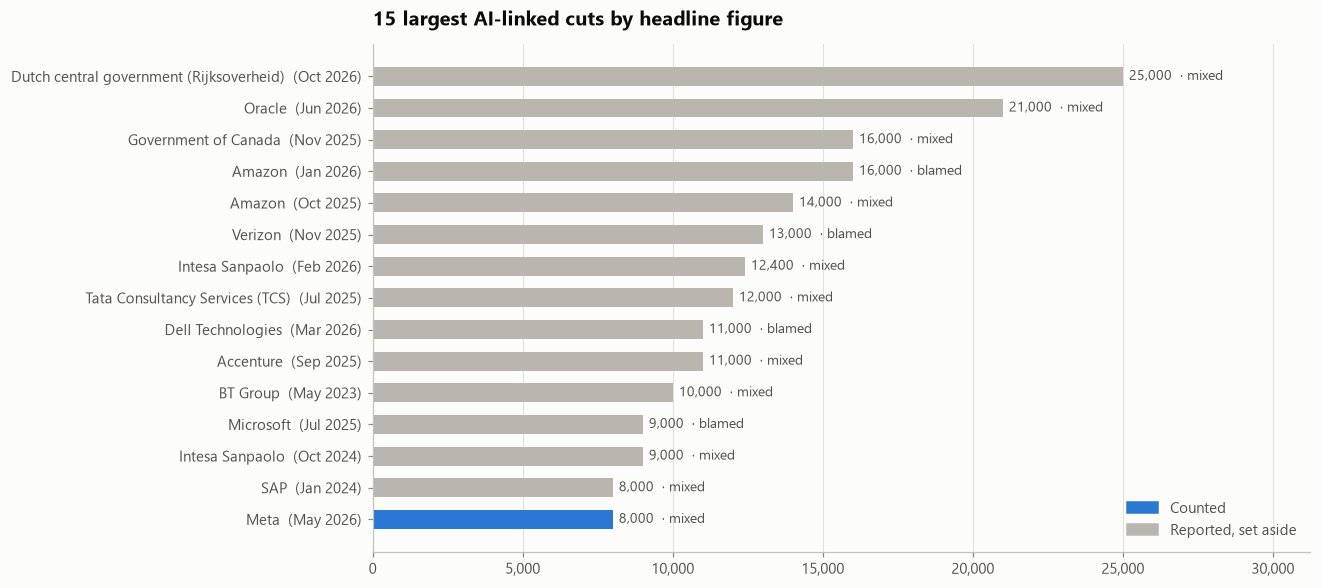

In [15]:
top = (cuts.dropna(subset=["Roles any"])
           .nlargest(15, "Roles any")[["Company", "Date", "Sector group", "Roles any", "Figure status", "Attribution"]]
           .sort_values("Roles any"))
labels = top["Company"] + "  (" + top["Date"].dt.strftime("%b %Y") + ")"

fig, ax = plt.subplots(figsize=(11, 6))
colors = [C[0] if s == "Counted" else GRAY for s in top["Figure status"]]
ax.barh(labels, top["Roles any"], color=colors, height=0.6)
for i, (v, a) in enumerate(zip(top["Roles any"], top["Attribution"])):
    ax.annotate(f"{v:,.0f}  · {a}", (v, i), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=INK2)
ax.xaxis.set_major_formatter(thousands)
ax.set_xlim(0, top["Roles any"].max() * 1.25)
ax.set_title("15 largest AI-linked cuts by headline figure")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=C[0]), plt.Rectangle((0, 0), 1, 1, color=GRAY)],
          labels=["Counted", "Reported, set aside"], loc="lower right")
ax.grid(axis="y", visible=False)
plt.show()

Headline figure per cut event (roles):


,count,mean,std,min,25%,50%,75%,90%,max
Roles any,301.0,1471.0,3148.0,3.0,100.0,300.0,1000.0,4000.0,25000.0


The 10 largest events make up 34% of all reported + counted roles: a very skewed distribution.


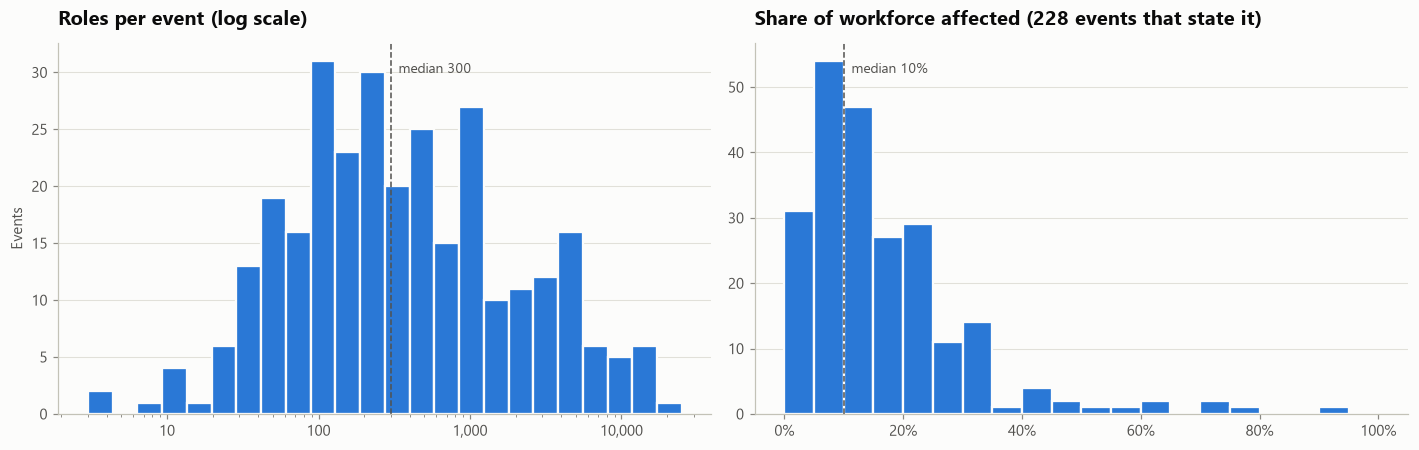

In [16]:
sized = cuts.dropna(subset=["Roles any"])
print("Headline figure per cut event (roles):")
display(sized["Roles any"].describe(percentiles=[.25, .5, .75, .9]).round(0).to_frame().T)

top10_share = sized.nlargest(10, "Roles any")["Roles any"].sum() / sized["Roles any"].sum() * 100
print(f"The 10 largest events make up {top10_share:.0f}% of all reported + counted roles: a very skewed distribution.")

pct = cuts["Pct workforce"].dropna()
pct = pct[pct <= 100]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
bins = np.logspace(np.log10(max(sized["Roles any"].min(), 1)), np.log10(sized["Roles any"].max()), 25)
axes[0].hist(sized["Roles any"], bins=bins, color=C[0], edgecolor="#fcfcfb", linewidth=1.5)
axes[0].set_xscale("log")
axes[0].xaxis.set_major_formatter(thousands)
axes[0].axvline(sized["Roles any"].median(), color=INK2, linestyle="--", linewidth=1)
axes[0].annotate(f"median {sized['Roles any'].median():,.0f}", (sized["Roles any"].median(), axes[0].get_ylim()[1] * 0.92),
                 xytext=(5, 0), textcoords="offset points", fontsize=9, color=INK2)
axes[0].set_title("Roles per event (log scale)")
axes[0].set_ylabel("Events")
axes[0].grid(axis="x", visible=False)

axes[1].hist(pct, bins=np.arange(0, 105, 5), color=C[0], edgecolor="#fcfcfb", linewidth=1.5)
axes[1].axvline(pct.median(), color=INK2, linestyle="--", linewidth=1)
axes[1].annotate(f"median {pct.median():.0f}%", (pct.median(), axes[1].get_ylim()[1] * 0.92),
                 xytext=(5, 0), textcoords="offset points", fontsize=9, color=INK2)
axes[1].xaxis.set_major_formatter(mticker.PercentFormatter())
axes[1].set_title(f"Share of workforce affected ({len(pct)} events that state it)")
axes[1].grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

In [17]:
# Do companies that blame AI explicitly cut a bigger share of staff?
pct_by_attr = (cuts.loc[cuts["Pct workforce"] <= 100]
                   .groupby("Attribution")["Pct workforce"]
                   .agg(events="count", median="median", mean="mean")
                   .reindex(ATTR).round(1))
pct_by_attr

,events,median,mean
Attribution,,,
explicit,20,22.0,23.2
mixed,166,11.2,15.2
blamed,42,9.5,12.6


## 9. Did the cuts actually happen?

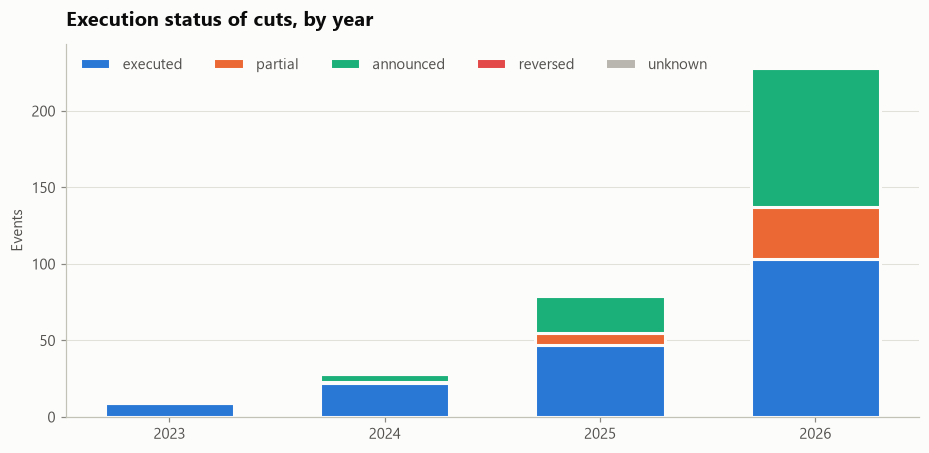

Reversed cuts (companies that walked an AI-linked layoff back):


,Company,Date,Attribution,What the employer said
54,CWT Italia (Carlson Wagonlit Travel),2026-10-05,blamed,Named no AI reason; others linked it to AI
72,Konecta,2026-09-11,blamed,Named no AI reason; others linked it to AI
287,Commonwealth Bank,2025-08-21,explicit,Declared the cut AI-related
307,Klarna,2025-06-04,explicit,Spoke about AI and headcount; no cut announced


In [18]:
EXEC = ["executed", "partial", "announced", "reversed", "unknown"]
ex = pd.crosstab(cuts["Year"], cuts["Execution"]).reindex(columns=EXEC, fill_value=0)

fig, ax = plt.subplots(figsize=(10, 4.4))
bottom = np.zeros(len(ex))
for k, col in zip(EXEC, C[:3] + [C[7], GRAY]):
    ax.bar(ex.index.astype(str), ex[k], bottom=bottom, color=col, label=k, width=0.6,
           edgecolor="#fcfcfb", linewidth=2)
    bottom += ex[k].values
ax.set_title("Execution status of cuts, by year")
ax.set_ylabel("Events")
ax.legend(ncol=5, loc="upper left")
ax.grid(axis="x", visible=False)
plt.show()

reversed_ = df[df["Execution"] == "reversed"][["Company", "Date", "Attribution", "What the employer said"]]
print("Reversed cuts (companies that walked an AI-linked layoff back):")
reversed_

## 10. Key takeaways

Computed from the data above, so they stay correct if you swap in a newer CSV.

In [19]:
y = roles_year
cur, prev = last.year, last.year - 1
ann = yearly.loc[cur, "events (annualised)"]
top_sec = sec["events"].idxmax()
top_fam = fam.idxmax()
blamed_share = (df["Attribution"] == "blamed").mean() * 100

takeaways = [
    f"Acceleration: {yearly.loc[prev, 'events']} events in {prev} vs {yearly.loc[cur, 'events']} so far in {cur} "
    f"(≈{ann:.0f} annualised, {ann / yearly.loc[prev, 'events']:.1f}× {prev}).",
    f"Headlines overstate the AI share: across all years {df['Roles counted'].sum():,.0f} roles are counted vs "
    f"{df['Roles reported (not counted)'].sum():,.0f} reported but set aside. Only "
    f"{100 * df['Roles counted'].sum() / df[['Roles counted', 'Roles reported (not counted)']].sum().sum():.0f}% of reported headcount survives the register's bar.",
    f"AI is rarely the sole stated reason: {explicit_share:.0f}% explicit, "
    f"{(df['Attribution'] == 'mixed').mean() * 100:.0f}% mixed, {blamed_share:.0f}% blamed by others only.",
    f"Most active sector group: {top_sec} ({sec.loc[top_sec, 'events']} cuts). The US accounts for {us_share:.0f}% of cuts.",
    f"Most-named job family: {top_fam} ({fam.max()} events), though {not_spec:.0f}% of cuts name no roles at all.",
    f"Cuts are typically small but the total is driven by a few giants: median {sized['Roles any'].median():,.0f} roles, "
    f"top-10 events = {top10_share:.0f}% of all roles; median share of workforce {pct.median():.0f}%.",
]
for t in takeaways:
    print("•", t, "\n")

• Acceleration: 88 events in 2025 vs 249 so far in 2026 (≈288 annualised, 3.3× 2025). 

• Headlines overstate the AI share: across all years 103,766 roles are counted vs 346,696 reported but set aside. Only 23% of reported headcount survives the register's bar. 

• AI is rarely the sole stated reason: 11% explicit, 64% mixed, 25% blamed by others only. 

• Most active sector group: Software & internet (149 cuts). The US accounts for 43% of cuts. 

• Most-named job family: Software engineering and IT (95 events), though 35% of cuts name no roles at all. 

• Cuts are typically small but the total is driven by a few giants: median 300 roles, top-10 events = 34% of all roles; median share of workforce 10%. 

